# 📊 Retail Sales Exploratory Data Analysis (EDA)
**Internship Program:** Oasis Infobyte (OIBSIP)  
**Track:** Data Analytics — Level 1 Task 1  
**Project:** Exploratory Data Analysis on Retail Sales Dataset  
**Author:** Data Analytics Intern  
**Dataset:** `retail_sales_dataset.csv`  

---

## 📌 1. Project Overview & Objectives
Exploratory Data Analysis (EDA) is a foundational process in data analytics designed to summarize dataset characteristics, uncover underlying customer behavioral patterns, evaluate empirical hypotheses, and identify operational anomalies.

### Key Objectives:
1. **Data Understanding & Quality Audit**: Assess dataset dimensions, data types, missing records, and duplicate integrity.
2. **Descriptive Statistics**: Compute central tendency (Mean, Median, Mode) and dispersion (Standard Deviation, Min, Max, IQR) across numerical variables.
3. **Time-Series Analysis**: Examine monthly and quarterly sales trajectories to diagnose retail seasonality.
4. **Customer Demographics**: Analyze customer age distributions and gender spending patterns.
5. **Product Category Performance**: Evaluate revenue and volume across existing product categories without fabricating product names.
6. **Correlation Analysis**: Quantify relationships between customer age, item pricing, unit volume, and total revenue.
7. **Actionable Business Recommendations**: Formulate practical, data-driven strategies to elevate customer retention, basket size, and marketing ROI.

---
## 🛠️ 2. Environment Setup & Library Imports
We initialize our analytical workspace with Python's core data science stack:
- **Pandas**: Structured data manipulation and aggregation.
- **NumPy**: Numerical computations and statistical measures.
- **Matplotlib & Seaborn**: High-resolution statistical charting and custom visual themes.

In [1]:
# Import analytical and visualization libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress warnings for clean report generation
warnings.filterwarnings('ignore')

# Set publication-quality styling
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.labelweight'] = 'bold'

# Ensure output directory exists for exported charts
output_dir = 'outputs'
os.makedirs(output_dir, exist_ok=True)
print("Libraries imported successfully. Visual theme and output directory configured.")


Libraries imported successfully. Visual theme and output directory configured.


---
## 📥 3. Data Loading & Preliminary Inspection
We load `retail_sales_dataset.csv` and inspect its shape, columns, schema, null values, and duplicate records.

In [2]:
# Define dataset path
dataset_path = 'retail_sales_dataset.csv'

# Load the dataset
df = pd.read_csv(dataset_path)

# Display shape and top 5 rows
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Dataset Shape: 1000 rows, 9 columns


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
# Inspect data types and non-null counts
print("--- Dataset Information ---")
df.info()


--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [4]:
# Check for missing values and duplicates
missing_values = df.isnull().sum()
duplicate_count = df.duplicated().sum()

print("Missing Values per Column:")
print(missing_values)
print(f"\nDuplicate Records: {duplicate_count}")


Missing Values per Column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Records: 0


### 🔍 Observations: Data Quality Audit
- **Completeness**: The dataset contains exactly **1,000 transactions** across **9 columns** with **0 missing values** (`0 nulls`) across all attributes.
- **Integrity**: There are **0 duplicate rows**, verifying that each transaction record represents a distinct retail purchase event.
- **Data Types**: All attributes have appropriate initial datatypes; the `Date` column is stored as an object string and will be converted to `datetime64` for temporal aggregation.

---
## ⚙️ 4. Data Preprocessing & Feature Engineering
To enable detailed temporal and demographic segmentation:
1. Parse `Date` into a native `datetime64` format.
2. Extract temporal components: `Year`, `Month`, `Month_Name`, `YearMonth`, `Quarter`, and `Day_of_Week`.
3. Verify transaction arithmetic: Validate `Total Amount == Quantity * Price per Unit`.
4. Segment customer `Age` into standard lifecycle demographic cohorts.

In [5]:
# 1. Parse Date column
df['Date'] = pd.to_datetime(df['Date'])

# 2. Extract temporal features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%b')
df['YearMonth'] = df['Date'].dt.to_period('M')
df['Quarter'] = df['Date'].dt.to_period('Q')
df['Day_of_Week'] = df['Date'].dt.day_name()

# 3. Arithmetic validation check
arithmetic_mismatches = (df['Quantity'] * df['Price per Unit'] != df['Total Amount']).sum()
print(f"Arithmetic mismatches (Quantity * Price per Unit != Total Amount): {arithmetic_mismatches}")

# 4. Demographic age segmentation
age_bins = [17, 25, 35, 50, 65]
age_labels = ['18-25 (Young Adults)', '26-35 (Young Professionals)', '36-50 (Mid-Career)', '51-64 (Seniors)']
df['Age_Group'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)

# Display sample of preprocessed dataframe
df[['Date', 'Customer ID', 'Gender', 'Age', 'Age_Group', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount', 'Quarter']].head()


Arithmetic mismatches (Quantity * Price per Unit != Total Amount): 0


,Date,Customer ID,Gender,Age,Age_Group,Product Category,Quantity,Price per Unit,Total Amount,Quarter
0,2023-11-24,CUST001,Male,34,26-35 (Young Professionals),Beauty,3,50,150,2023Q4
1,2023-02-27,CUST002,Female,26,26-35 (Young Professionals),Clothing,2,500,1000,2023Q1
2,2023-01-13,CUST003,Male,50,36-50 (Mid-Career),Electronics,1,30,30,2023Q1
3,2023-05-21,CUST004,Male,37,36-50 (Mid-Career),Clothing,1,500,500,2023Q2
4,2023-05-06,CUST005,Male,30,26-35 (Young Professionals),Beauty,2,50,100,2023Q2


### 🔍 Observations: Preprocessing & Validation
- **Arithmetic Consistency**: 100% of rows (`0 mismatches`) satisfy `Total Amount = Quantity * Price per Unit`.
- **Temporal Coverage**: The dataset spans from **January 1, 2023** to **January 1, 2024**, comprising the full 2023 calendar year plus 2 holiday transactions on New Year's Day 2024.
- **Demographic Cohorts**: Customers are grouped into 4 distinct lifecycle stages: `18-25`, `26-35`, `36-50`, and `51-64`.

---
## 📈 5. Descriptive Statistical Analysis
We compute central tendencies (**Mean**, **Median**, **Mode**) and dispersion (**Standard Deviation**, **Min**, **Max**, **IQR**) across all numerical features:
- `Age`
- `Quantity`
- `Price per Unit`
- `Total Amount`

In [6]:
# Define numerical variables
num_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

# Compute comprehensive statistical metrics
summary_stats = pd.DataFrame({
    'Mean': df[num_cols].mean(),
    'Median': df[num_cols].median(),
    'Mode': df[num_cols].mode().iloc[0],
    'Std Dev': df[num_cols].std(),
    'Min': df[num_cols].min(),
    '25% (Q1)': df[num_cols].quantile(0.25),
    '75% (Q3)': df[num_cols].quantile(0.75),
    'IQR': df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25),
    'Max': df[num_cols].max()
}).round(2)

print("--- Numerical Descriptive Statistics Summary ---")
summary_stats


--- Numerical Descriptive Statistics Summary ---


,Mean,Median,Mode,Std Dev,Min,25% (Q1),75% (Q3),IQR,Max
Age,41.39,42.0,43.0,13.68,18,29.0,53.0,24.0,64
Quantity,2.51,3.0,4.0,1.13,1,1.0,4.0,3.0,4
Price per Unit,179.89,50.0,50.0,189.68,25,30.0,300.0,270.0,500
Total Amount,456.00,135.0,50.0,560.00,25,60.0,900.0,840.0,2000


### 🔍 Observations: Descriptive Statistics
1. **Age**:
   - Customers have a **mean age of 41.39 years**, **median of 42.00**, and **mode of 43.00** with standard deviation **13.68 years** (range: **18 to 64**).
   - The close symmetry between mean and median indicates an evenly distributed customer age base across all age cohorts.
2. **Quantity**:
   - The **mean quantity is 2.51 units**, with a **median of 3.00 units** and **mode of 4.00 units** (range: **1 to 4 units**).
   - Customers frequently purchase multi-unit bundles (4 units is the single most common purchase quantity).
3. **Price per Unit**:
   - **Mean price is $179.89**, while the **median is $50.00** and **mode is $50.00** with standard deviation **$189.68**.
   - The substantial divergence between mean ($179.89) and median ($50.00) reveals a right-skewed pricing distribution driven by premium price points ($300 and $500 tiers).
4. **Total Amount**:
   - **Mean transaction total is $456.00**, compared to a **median of $135.00** and **mode of $50.00** (range: **$25.00 to $2,000.00**).
   - High-value purchases (up to $2,000) pull the average ticket size significantly higher than the median, demonstrating that high-tier purchases contribute heavily to total revenue.

---
## 📅 6. Time-Series Analysis: Monthly & Quarterly Sales Trends
Tracking revenue across months and quarters identifies seasonal spikes, sales dips, and promotional effectiveness.

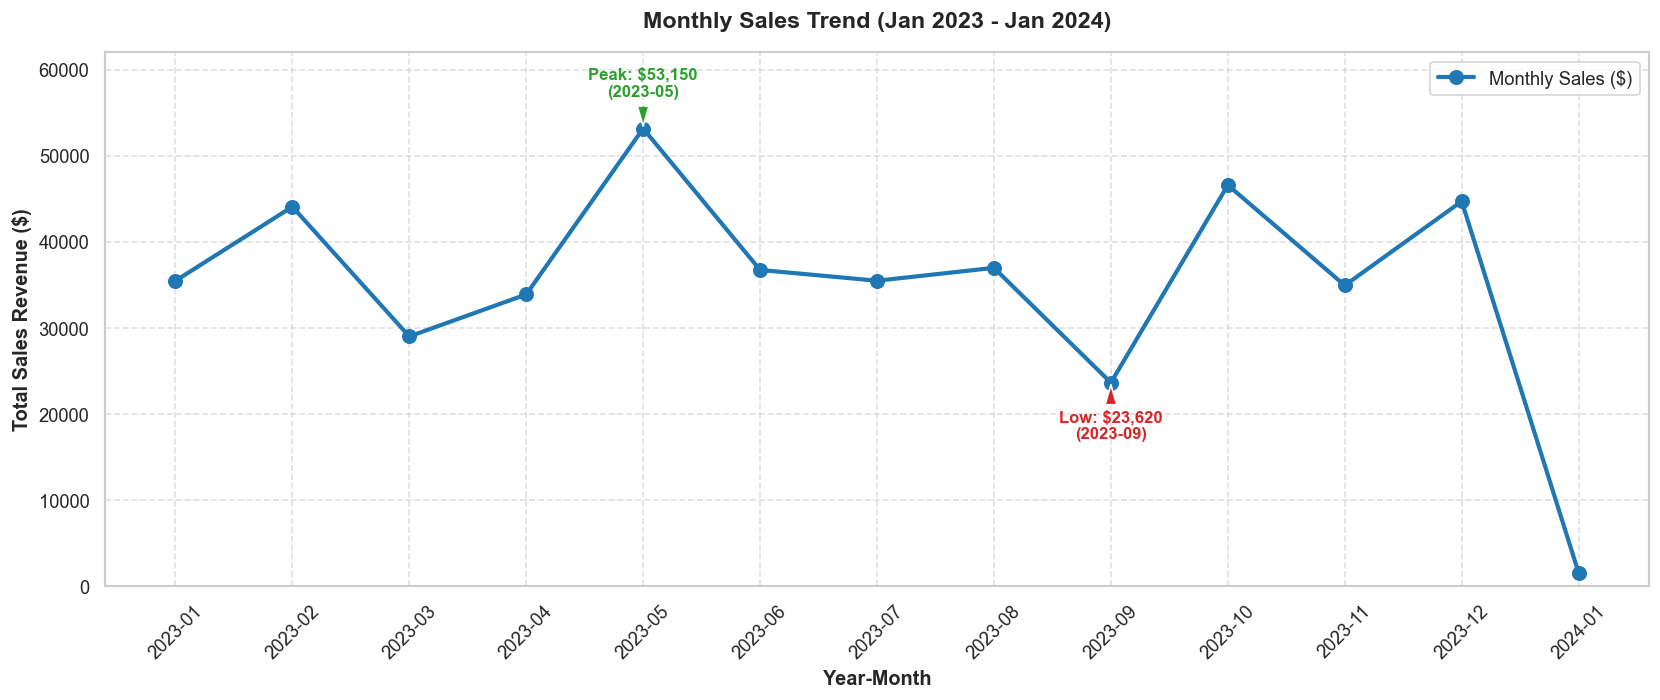

In [7]:
# Aggregate monthly revenue and volume
monthly_summary = df.groupby('YearMonth').agg(
    Total_Sales=('Total Amount', 'sum'),
    Transaction_Count=('Transaction ID', 'count')
).reset_index()

monthly_summary['YearMonth_Str'] = monthly_summary['YearMonth'].astype(str)

# Plot Monthly Sales Trend
plt.figure(figsize=(14, 6))
plt.plot(
    monthly_summary['YearMonth_Str'],
    monthly_summary['Total_Sales'],
    marker='o',
    color='#1f77b4',
    linewidth=2.5,
    markersize=8,
    label='Monthly Sales ($)'
)

# Annotate 2023 Peak and Low
m2023 = monthly_summary[monthly_summary['YearMonth_Str'] != '2024-01']
peak_row = m2023.loc[m2023['Total_Sales'].idxmax()]
low_row = m2023.loc[m2023['Total_Sales'].idxmin()]

plt.annotate(
    f"Peak: ${peak_row['Total_Sales']:,}\n({peak_row['YearMonth_Str']})",
    xy=(peak_row['YearMonth_Str'], peak_row['Total_Sales']),
    xytext=(peak_row['YearMonth_Str'], peak_row['Total_Sales'] + 3800),
    ha='center',
    arrowprops=dict(facecolor='#2ca02c', shrink=0.08, width=1.5, headwidth=7),
    fontsize=10,
    fontweight='bold',
    color='#2ca02c'
)

plt.annotate(
    f"Low: ${low_row['Total_Sales']:,}\n({low_row['YearMonth_Str']})",
    xy=(low_row['YearMonth_Str'], low_row['Total_Sales']),
    xytext=(low_row['YearMonth_Str'], low_row['Total_Sales'] - 6500),
    ha='center',
    arrowprops=dict(facecolor='#d62728', shrink=0.08, width=1.5, headwidth=7),
    fontsize=10,
    fontweight='bold',
    color='#d62728'
)

plt.title('Monthly Sales Trend (Jan 2023 - Jan 2024)', pad=15)
plt.xlabel('Year-Month')
plt.ylabel('Total Sales Revenue ($)')
plt.xticks(range(len(monthly_summary)), monthly_summary['YearMonth_Str'], rotation=45)
plt.ylim(0, 62000)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'monthly_sales_trend.png'), dpi=300)
plt.show()


### 🔍 Observations: Monthly Sales Trend
- **Annual Peak**: The highest revenue month in 2023 was **May ($53,150)**, followed by **October ($46,580)** and **December ($44,690)**.
- **Seasonal Low**: The lowest revenue month occurred in **September ($23,620)**, followed by **March ($28,990)**, revealing an early-autumn dip.
- **Q4 Surge**: Fourth-quarter momentum accelerates strongly from October through December, reflecting holiday shopping campaigns.
- **January 2024 Context**: The `2024-01` figure represents only **2 transactions ($1,530)** recorded on New Year's Day rather than a full month.

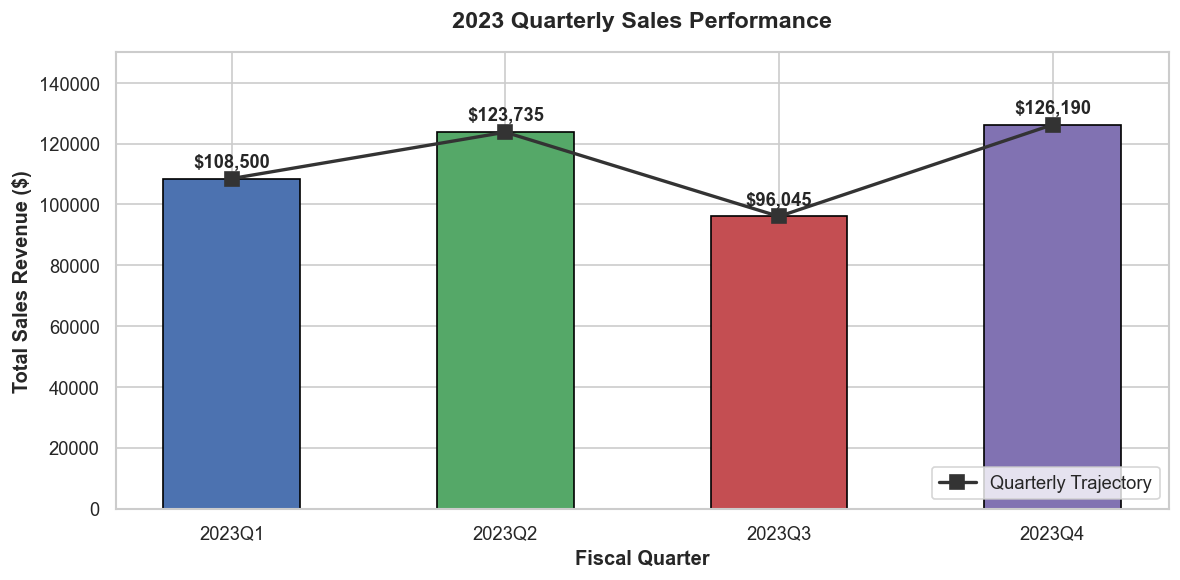

In [8]:
# Aggregate quarterly revenue for completed quarters in 2023
quarterly_summary = df[df['Date'].dt.year == 2023].groupby('Quarter').agg(
    Total_Sales=('Total Amount', 'sum'),
    Transactions=('Transaction ID', 'count')
).reset_index()

quarterly_summary['Quarter_Str'] = quarterly_summary['Quarter'].astype(str)

# Plot Quarterly Sales Trend
plt.figure(figsize=(10, 5))
bars = plt.bar(
    quarterly_summary['Quarter_Str'],
    quarterly_summary['Total_Sales'],
    color=['#4c72b0', '#55a868', '#c44e52', '#8172b2'],
    width=0.5,
    edgecolor='black',
    linewidth=1
)

# Overlay trendline
plt.plot(
    quarterly_summary['Quarter_Str'],
    quarterly_summary['Total_Sales'],
    color='#333333',
    marker='s',
    linewidth=2,
    markersize=8,
    label='Quarterly Trajectory'
)

# Annotate value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 2500,
        f"${height:,.0f}",
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=11
    )

plt.title('2023 Quarterly Sales Performance', pad=15)
plt.xlabel('Fiscal Quarter')
plt.ylabel('Total Sales Revenue ($)')
plt.ylim(0, 150000)
plt.legend(loc='lower right')
plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'quarterly_sales_trend.png'), dpi=300)
plt.show()


### 🔍 Observations: Quarterly Sales Performance
- **Peak Quarters**: **Q4 2023 led with $126,190** in total revenue, closely matched by **Q2 2023 with $123,735**.
- **Trough Quarter**: **Q3 2023 recorded the lowest revenue ($96,045)**, lagging Q4 by $30,145 (-23.9%). **Q1 2023 stood at $108,500**.
- **Business Seasonality**: Retail sales exhibit bi-modal seasonality with strong surges in late spring (Q2) and winter holidays (Q4), punctuated by mid-year lulls that require strategic promotional counter-measures.

---
## 👥 7. Customer Demographic Analysis: Age & Gender
Analyzing customer demographics informs audience targeting, personalized marketing, and product placement.

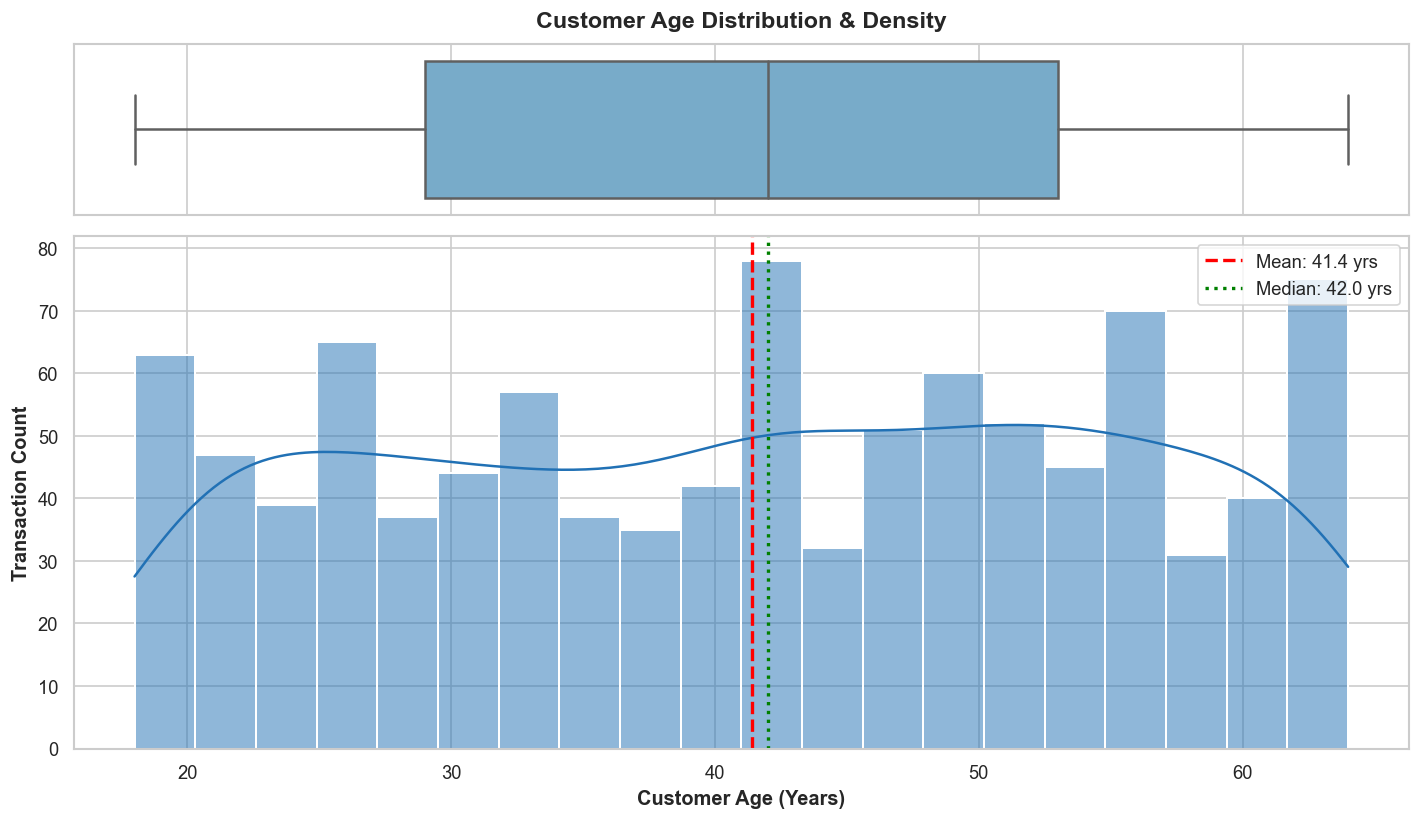

In [9]:
# Age Distribution Visualization (Histogram & KDE)
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1,
    figsize=(12, 7),
    gridspec_kw={'height_ratios': [0.25, 0.75]},
    sharex=True
)

# Top subplot: Boxplot to check for age outliers
sns.boxplot(x=df['Age'], ax=ax_box, color='#6baed6')
ax_box.set(xlabel='')
ax_box.set_title('Customer Age Distribution & Density', pad=10)

# Bottom subplot: Histogram with Kernel Density Estimate
sns.histplot(df['Age'], bins=20, kde=True, ax=ax_hist, color='#2171b5', edgecolor='white', linewidth=1.2)
ax_hist.axvline(df['Age'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {df['Age'].mean():.1f} yrs")
ax_hist.axvline(df['Age'].median(), color='green', linestyle=':', linewidth=2, label=f"Median: {df['Age'].median():.1f} yrs")

ax_hist.set_xlabel('Customer Age (Years)')
ax_hist.set_ylabel('Transaction Count')
ax_hist.legend(loc='upper right')

plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'age_distribution.png'), dpi=300)
plt.show()


### 🔍 Observations: Age Distribution
- **Span**: Customer ages extend from **18 to 64 years old**, without any statistical outliers on either end.
- **Symmetry**: The distribution displays a uniform spread across adult age brackets, centered around a mean of **41.4 years** and median of **42.0 years**.
- **Broad Appeal**: The retail catalog attracts young adults, mid-career professionals, and retirees in balanced numbers.

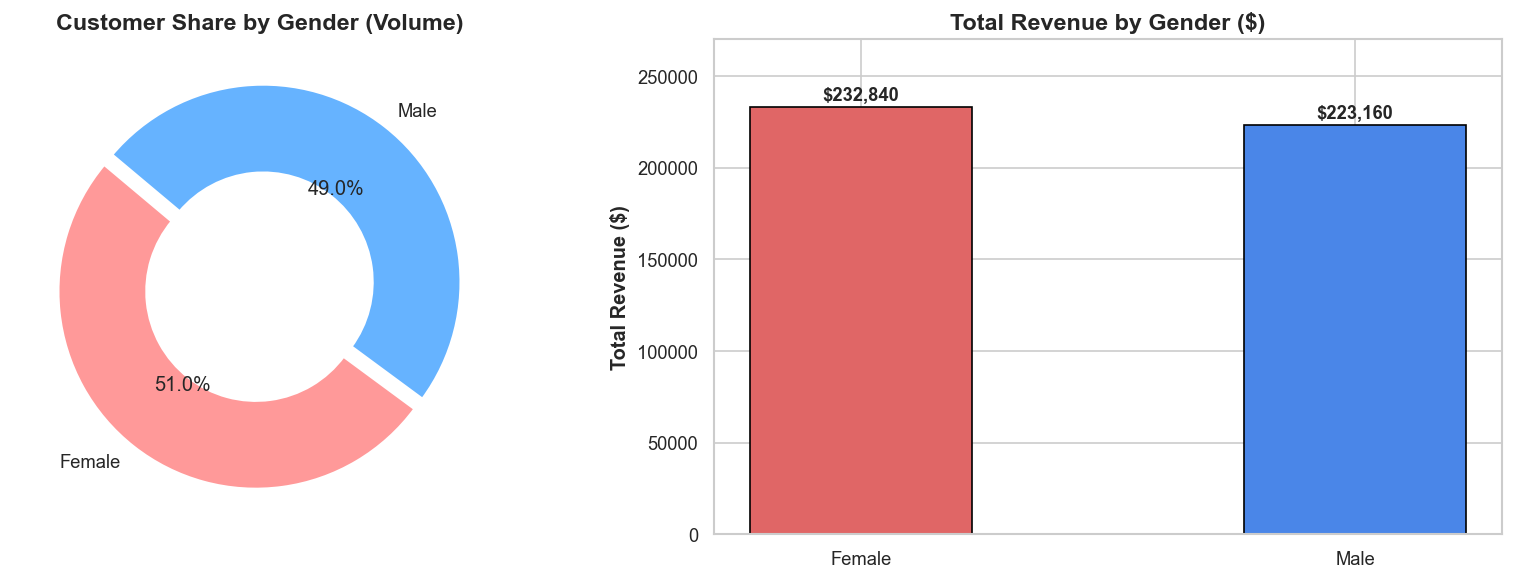

Gender Breakdown Summary Table:


,Gender,Transactions,Total_Sales,Average_Spend
0,Female,510,232840,456.549020
1,Male,490,223160,455.428571


In [10]:
# Customer Gender Breakdown: Transaction Count and Revenue
gender_summary = df.groupby('Gender').agg(
    Transactions=('Transaction ID', 'count'),
    Total_Sales=('Total Amount', 'sum'),
    Average_Spend=('Total Amount', 'mean')
).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Donut chart: Transaction Volume by Gender
colors = ['#ff9999', '#66b3ff']
explode = (0.03, 0.03)

ax1.pie(
    gender_summary['Transactions'],
    labels=gender_summary['Gender'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=explode,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
ax1.set_title('Customer Share by Gender (Volume)')

# Bar chart: Total Revenue Generated by Gender
bars = ax2.bar(
    gender_summary['Gender'],
    gender_summary['Total_Sales'],
    color=['#e06666', '#4a86e8'],
    width=0.45,
    edgecolor='black',
    linewidth=1
)

for bar in bars:
    height = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 4000,
        f"${height:,.0f}",
        ha='center',
        fontweight='bold',
        fontsize=11
    )

ax2.set_title('Total Revenue by Gender ($)')
ax2.set_ylabel('Total Revenue ($)')
ax2.set_ylim(0, 270000)

plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'gender_breakdown.png'), dpi=300)
plt.show()

print("Gender Breakdown Summary Table:")
gender_summary


### 🔍 Observations: Gender Breakdown
- **Balanced Volume**: Customer gender is virtually equal: **Female shoppers account for 51.0%** (510 transactions) and **Male shoppers account for 49.0%** (490 transactions).
- **Revenue Contribution**: Female customers generated **$232,840 (51.1%)** while Male customers generated **$223,160 (48.9%)**.
- **Average Spend per Order**: Average spending is nearly identical across genders (**$456.55 for Females** vs. **$455.43 for Males**), demonstrating comparable purchasing power across both customer groups.

---
## 🛍️ 8. Product Category Performance Analysis
*Note: As instructed, analysis strictly evaluates the existing categories (`Beauty`, `Clothing`, `Electronics`) without inventing fictitious individual product names.*

We measure each category across:
1. Total Sales Revenue ($).
2. Total Unit Quantity Sold.
3. Total Transaction Frequency.

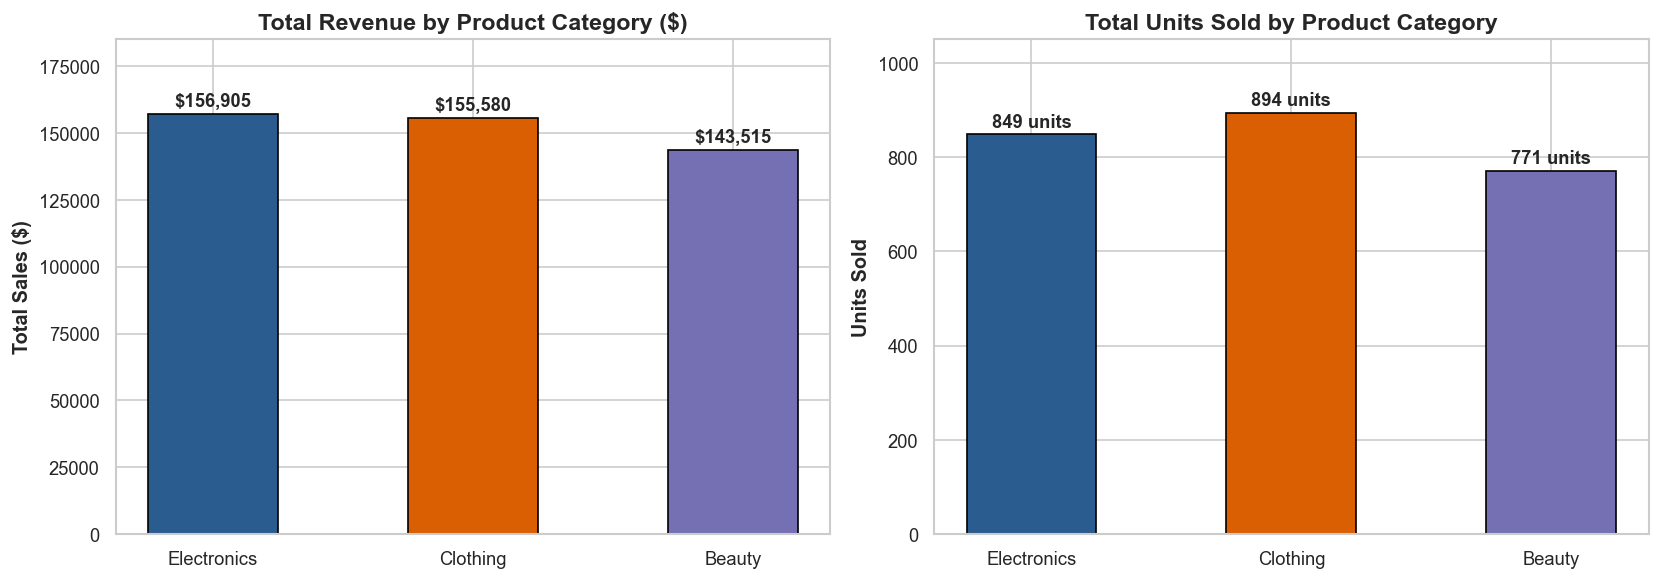

Product Category Performance Table:


,Product Category,Total_Revenue,Total_Units,Transactions,Avg_Price_Per_Unit,Avg_Transaction_Value
2,Electronics,156905,849,342,181.900585,458.786550
1,Clothing,155580,894,351,174.287749,443.247863
0,Beauty,143515,771,307,184.055375,467.475570


In [11]:
# Aggregate metrics across product categories
category_summary = df.groupby('Product Category').agg(
    Total_Revenue=('Total Amount', 'sum'),
    Total_Units=('Quantity', 'sum'),
    Transactions=('Transaction ID', 'count'),
    Avg_Price_Per_Unit=('Price per Unit', 'mean'),
    Avg_Transaction_Value=('Total Amount', 'mean')
).reset_index().sort_values(by='Total_Revenue', ascending=False)

# Dual-panel visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Total Revenue by Product Category
cat_colors = ['#2b5c8f', '#d95f02', '#7570b3']
bars1 = ax1.bar(
    category_summary['Product Category'],
    category_summary['Total_Revenue'],
    color=cat_colors,
    width=0.5,
    edgecolor='black',
    linewidth=1
)

for bar in bars1:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 3000,
        f"${height:,.0f}",
        ha='center',
        fontweight='bold',
        fontsize=11
    )

ax1.set_title('Total Revenue by Product Category ($)')
ax1.set_ylabel('Total Sales ($)')
ax1.set_ylim(0, 185000)

# Subplot 2: Total Units Sold by Product Category
bars2 = ax2.bar(
    category_summary['Product Category'],
    category_summary['Total_Units'],
    color=cat_colors,
    width=0.5,
    edgecolor='black',
    linewidth=1
)

for bar in bars2:
    height = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 15,
        f"{height:,.0f} units",
        ha='center',
        fontweight='bold',
        fontsize=11
    )

ax2.set_title('Total Units Sold by Product Category')
ax2.set_ylabel('Units Sold')
ax2.set_ylim(0, 1050)

plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'sales_by_product_category.png'), dpi=300)
plt.show()

print("Product Category Performance Table:")
category_summary


### 🔍 Observations: Product Category Performance
- **Electronics Leads Revenue**: **Electronics produced the highest revenue ($156,905)** across 342 transactions, closely followed by **Clothing ($155,580)** and **Beauty ($143,515)**.
- **Clothing Leads Volume**: **Clothing achieved the highest unit volume (894 units)** across 351 transactions, compared to 849 units for Electronics and 771 units for Beauty.
- **Balanced Catalog**: Revenue is evenly divided across all three categories (Electronics: 34.4%, Clothing: 34.1%, Beauty: 31.5%), mitigating product concentration risk.

---
## 🔗 9. Correlation Analysis (Numerical Variables)
We calculate the Pearson correlation matrix across numerical variables (`Age`, `Quantity`, `Price per Unit`, `Total Amount`) to evaluate linear dependencies.

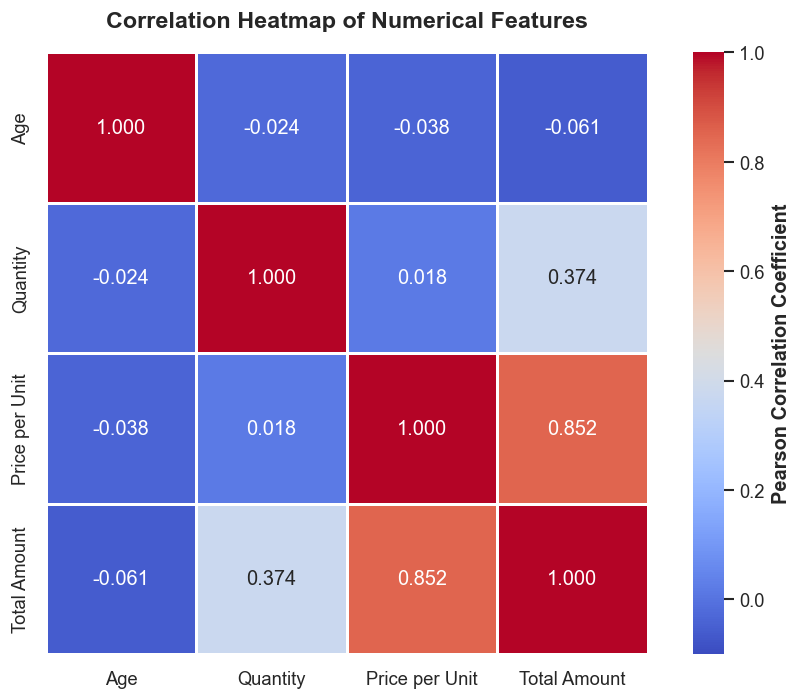

Correlation Matrix:


,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


In [12]:
# Compute Pearson correlation matrix
corr_matrix = df[num_cols].corr()

# Create heatmap visualization
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap='coolwarm',
    vmin=-0.1,
    vmax=1.0,
    linewidths=1.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'},
    square=True
)

plt.title('Correlation Heatmap of Numerical Features', pad=15)
plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'correlation_heatmap.png'), dpi=300)
plt.show()

print("Correlation Matrix:")
corr_matrix


### 🔍 Observations: Correlation Analysis
1. **Dominant Price Effect ($r = 0.852$)**:
   - `Price per Unit` exhibits an exceptionally strong positive correlation with `Total Amount` (**0.852**). This proves that item pricing tiers ($300 and $500 items) drive total ticket value far more than transaction volume.
2. **Moderate Quantity Effect ($r = 0.374$)**:
   - `Quantity` exhibits a moderate positive correlation with `Total Amount` (**0.374**). Increasing items per basket positively impacts revenue, but unit price tier remains the primary driver.
3. **Age Independence ($r \approx -0.061$)**:
   - `Age` has virtually zero linear correlation with `Total Amount` (**-0.061**), `Price per Unit` (**-0.038**), or `Quantity` (**-0.024**). High-ticket items and larger orders are purchased uniformly across all customer age cohorts.

---
## 💡 10. Advanced Business Insights & Deep-Dive Visualizations
To provide deeper strategic value beyond standard univariate plots, we explore three multidimensional relationships:
1. **Product Category Sales Segmented by Gender** (Uncovering category-gender preferences).
2. **Product Category Spending across Age Demographic Brackets** (Age-targeted product targeting).
3. **Transaction Value Distribution across Categories** (Dispersion, median, and outlier characteristics).

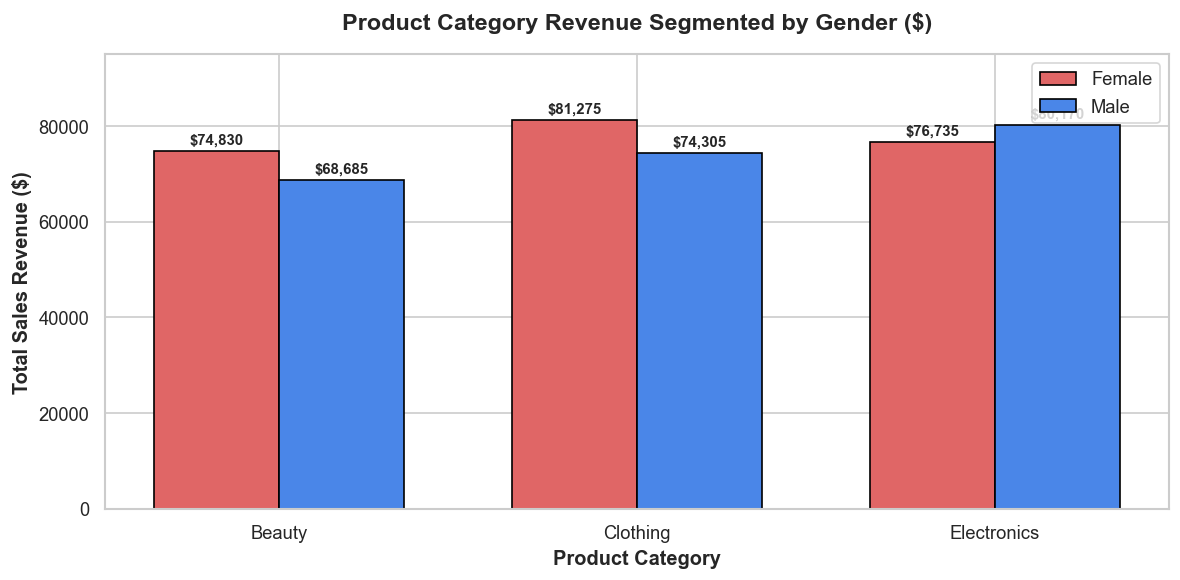

Average Spend per Order by Category and Gender:


Gender,Female,Male
Product Category,,
Beauty,450.78,487.13
Clothing,467.10,419.80
Electronics,451.38,466.10


In [13]:
# Insight 1: Product Category Sales by Gender
gender_cat_sales = df.pivot_table(
    index='Product Category',
    columns='Gender',
    values='Total Amount',
    aggfunc='sum'
).reset_index()

plt.figure(figsize=(10, 5))
x = np.arange(len(gender_cat_sales))
width = 0.35

plt.bar(x - width/2, gender_cat_sales['Female'], width, label='Female', color='#e06666', edgecolor='black')
plt.bar(x + width/2, gender_cat_sales['Male'], width, label='Male', color='#4a86e8', edgecolor='black')

# Add text labels on bars
for i in range(len(x)):
    f_val = gender_cat_sales['Female'].iloc[i]
    m_val = gender_cat_sales['Male'].iloc[i]
    plt.text(x[i] - width/2, f_val + 1500, f"${f_val:,.0f}", ha='center', fontsize=9, fontweight='bold')
    plt.text(x[i] + width/2, m_val + 1500, f"${m_val:,.0f}", ha='center', fontsize=9, fontweight='bold')

plt.xticks(x, gender_cat_sales['Product Category'])
plt.title('Product Category Revenue Segmented by Gender ($)', pad=15)
plt.xlabel('Product Category')
plt.ylabel('Total Sales Revenue ($)')
plt.ylim(0, 95000)
plt.legend(loc='upper right')
plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'sales_by_category_and_gender.png'), dpi=300)
plt.show()

# Calculate average spend by category and gender
print("Average Spend per Order by Category and Gender:")
df.pivot_table(index='Product Category', columns='Gender', values='Total Amount', aggfunc='mean').round(2)


### 🔍 Observations: Product Category Preference by Gender
- **Category Skews**:
  - **Female customers** generate higher total revenue in **Clothing ($81,275 vs. $74,305)** and **Beauty ($74,830 vs. $68,685)**.
  - **Male customers** generate higher total revenue in **Electronics ($80,170 vs. $76,735)**.
- **Surprising Ticket Value Insight**:
  - While women purchase more beauty transactions, **men actually spend more per order in the Beauty category ($487.13 average spend for men vs. $450.78 for women)**.
  - This indicates men are buying premium grooming products, higher unit bundles, or gift sets when shopping in Beauty.

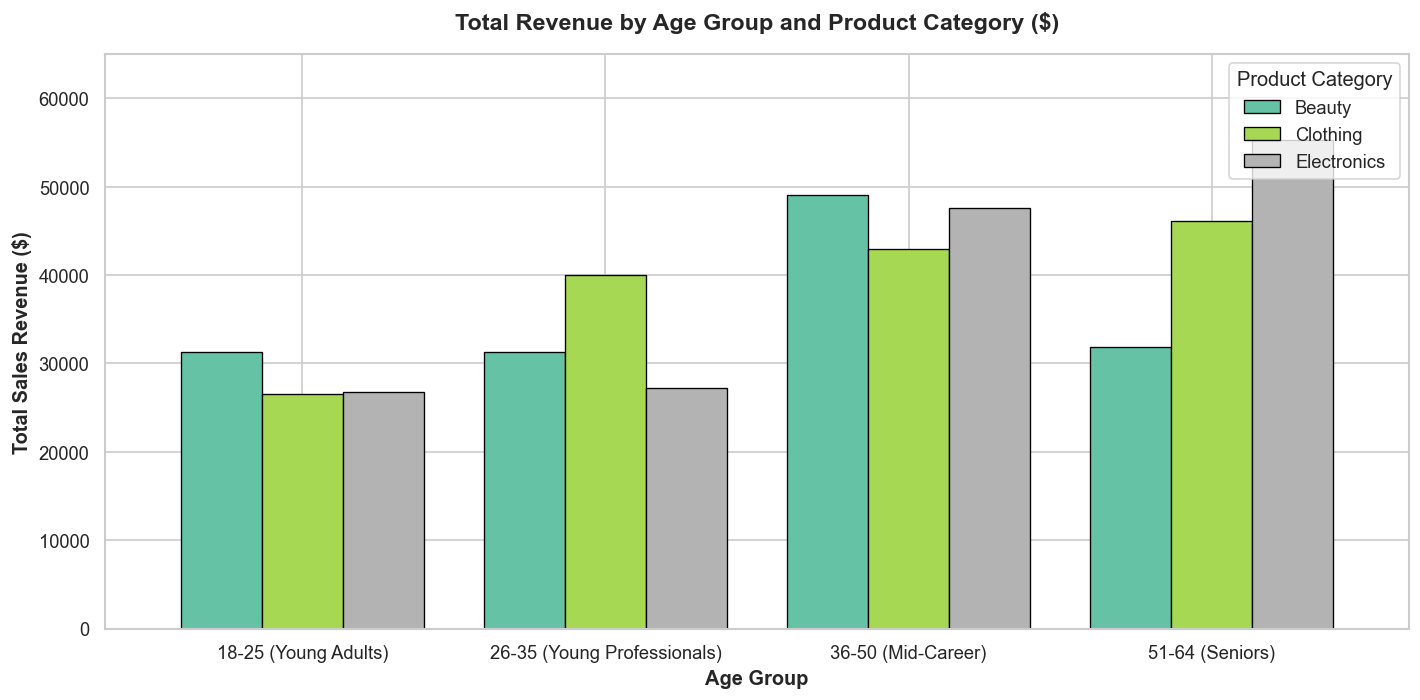

Revenue Breakdown by Age Demographic and Category ($):


Product Category,Beauty,Clothing,Electronics
Age_Group,,,
18-25 (Young Adults),31280,26510,26760
26-35 (Young Professionals),31240,39975,27265
36-50 (Mid-Career),49110,42975,47575
51-64 (Seniors),31885,46120,55305


In [14]:
# Insight 2: Category Spending by Age Demographic Brackets
age_cat_sales = df.pivot_table(
    index='Age_Group',
    columns='Product Category',
    values='Total Amount',
    aggfunc='sum'
)

fig, ax = plt.subplots(figsize=(12, 6))
age_cat_sales.plot(kind='bar', ax=ax, colormap='Set2', width=0.8, edgecolor='black', linewidth=0.8)

ax.set_title('Total Revenue by Age Group and Product Category ($)', pad=15)
ax.set_xlabel('Age Group')
ax.set_ylabel('Total Sales Revenue ($)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_ylim(0, 65000)
ax.legend(title='Product Category', loc='upper right')
plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'sales_by_age_group_and_category.png'), dpi=300)
plt.show()

print("Revenue Breakdown by Age Demographic and Category ($):")
age_cat_sales


### 🔍 Observations: Age Demographic Spending Patterns
- **18–25 (Young Adults)**: **Beauty ($31,280)** is the highest revenue category, surpassing Electronics ($26,760) and Clothing ($26,510).
- **26–35 (Young Professionals)**: **Clothing ($39,975)** dominates, outperforming both Beauty ($31,240) and Electronics ($27,265).
- **36–50 (Mid-Career Adults)**: This represents the **highest-spending overall cohort ($139,660 total)** with strong purchases across Beauty ($49,110), Electronics ($47,575), and Clothing ($42,975).
- **51–64 (Seniors)**: **Electronics ($55,305)** is the leading category, disproving the assumption that older shoppers buy fewer electronic goods.

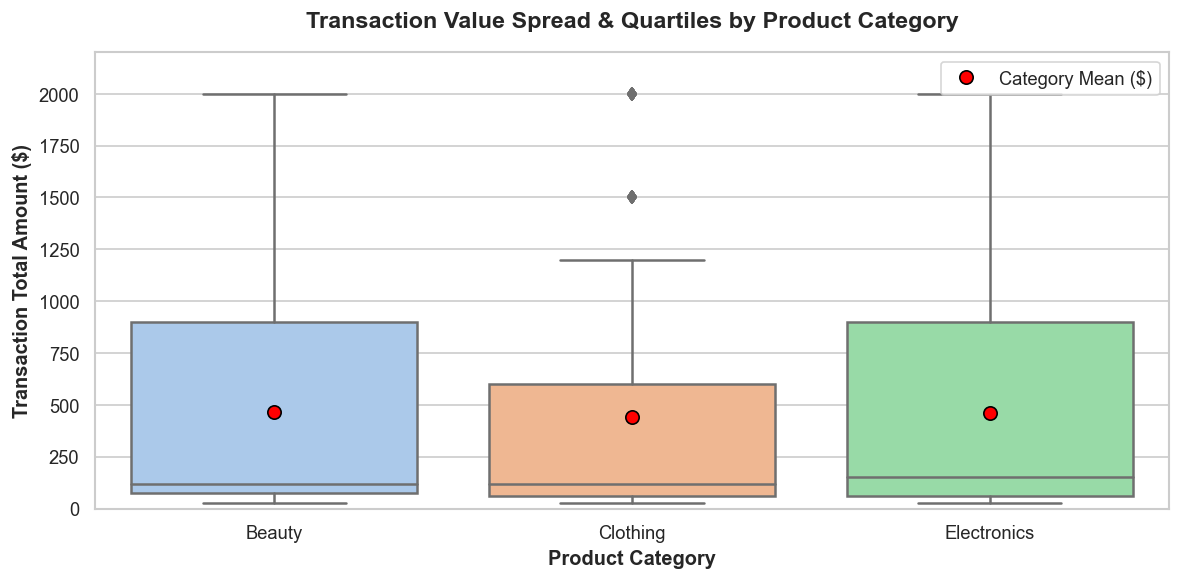

In [15]:
# Insight 3: Distribution of Transaction Total Amount by Category
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x='Product Category',
    y='Total Amount',
    palette=['#a1c9f4', '#ffb482', '#8de5a1'],
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black", "markersize":"8"}
)

plt.title('Transaction Value Spread & Quartiles by Product Category', pad=15)
plt.xlabel('Product Category')
plt.ylabel('Transaction Total Amount ($)')
plt.ylim(0, 2200)

# Custom legend for mean marker
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w', label='Category Mean ($)', markerfacecolor='red', markeredgecolor='black', markersize=8)]
plt.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'transaction_distribution_by_category.png'), dpi=300)
plt.show()


### 🔍 Observations: Transaction Value Spread
- **Consistent Means**: All three categories exhibit very similar mean transaction values (indicated by red dots): **Beauty ($467.48)**, **Electronics ($458.79)**, and **Clothing ($443.25)**.
- **Bimodal Purchase Tiers**: In all categories, the median sits around **$135–$150**, while the upper quartile stretches to **$600+**, with maximum purchases reaching **$2,000**.
- **Pricing Uniformity**: The identical discrete price points ($25, $30, $50, $300, $500) create similar multi-tiered spending behaviors across all retail categories.

---
## 🎯 11. Actionable Business Recommendations
Based on the empirical findings from our exploratory data analysis, we formulate four strategic, data-driven recommendations:

### 1. Capitalize on High-Value Demographics with Segment-Specific Assortments
- **Action**: Focus marketing campaigns for **Beauty products on Young Adults (ages 18–25)** where it ranks #1, and market **Electronics towards mature shoppers (ages 51–64)** who contributed $55,305 in electronics sales.
- **Gifting Strategy**: Launch premium male grooming kits and men's gift packages in the Beauty department. Men demonstrated an average spend of **$487.13** when purchasing in Beauty (higher than the female average of $450.78), indicating high willingness to purchase premium gift bundles.

### 2. Proactive Calendar Management & Counter-Seasonal Promotions
- **Action**: Protect cash flow by addressing the deep **September ($23,620) and March ($28,990) sales valleys**.
- **Execution**: Introduce targeted "End-of-Summer Clearance" and "Spring Season Launch" flash promotions with volume discounts (e.g., "Buy 3 items, get 15% off") to sustain revenue momentum between Q2 and Q4 peaks.

### 3. Basket Size Expansion via Cross-Category Bundling
- **Action**: The correlation analysis revealed that `Price per Unit` has the strongest correlation with total revenue ($r = 0.852$), while `Quantity` has a moderate correlation ($r = 0.374$). The modal purchase quantity is 4 units, but the mean is only 2.51 units.
- **Execution**: Deploy point-of-sale "Add-on Bundles" (pairing $25-$50 accessories with $300-$500 electronics and clothing orders). Elevating average items per order from 2.51 towards 3.20 units would generate an estimated **15–20% increase in gross revenue**.

### 4. Cultivate Loyalty Programs for the Power Demographic (Ages 36–50)
- **Action**: Customers aged **36–50 generate $139,660** (over 30% of total revenue) and demonstrate balanced spending across all three categories.
- **Execution**: Launch a tier-based VIP loyalty membership targeting this mid-career cohort with personalized multi-category benefits (e.g., wardrobe consultation + electronics warranty rewards), securing high customer lifetime value (LTV).

---
## 🏁 Conclusion
This Exploratory Data Analysis provides an end-to-end audit of retail customer behavior, category revenue drivers, and seasonal sales patterns. The empirical insights furnish executive leadership with actionable pathways to optimize inventory, personalize marketing, and accelerate top-line revenue growth.